# Exploatory data analysis

### General EDA

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

In [5]:
df = pd.read_csv("supply_chain.csv")

In [6]:
df.head()

,date,product_id,category,supplier_id,demand,inventory_level,orders,price,promotion,lead_time_days,supplier_rating,transport_cost,warehouse_capacity,stockout
0,2023-01-01,P0016,Groceries,S008,57,230,60,148.29,No,9,4.0,89.39,750,No
1,2023-01-01,P0034,Personal Care,S018,101,158,84,42.52,No,7,3.1,54.61,750,No
2,2023-01-01,P0057,Groceries,S019,187,541,167,106.03,Yes,14,3.6,102.61,1000,No
3,2023-01-01,P0044,Electronics,S029,66,179,51,403.41,No,12,3.8,109.51,1000,No
4,2023-01-01,P0058,Furniture,S004,35,125,27,1221.83,Yes,12,4.1,111.11,5000,No


In [7]:
df.shape

(6000, 14)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                6000 non-null   str    
 1   product_id          6000 non-null   str    
 2   category            6000 non-null   str    
 3   supplier_id         6000 non-null   str    
 4   demand              6000 non-null   int64  
 5   inventory_level     6000 non-null   int64  
 6   orders              6000 non-null   int64  
 7   price               6000 non-null   float64
 8   promotion           6000 non-null   str    
 9   lead_time_days      6000 non-null   int64  
 10  supplier_rating     6000 non-null   float64
 11  transport_cost      6000 non-null   float64
 12  warehouse_capacity  6000 non-null   int64  
 13  stockout            6000 non-null   str    
dtypes: float64(3), int64(5), str(6)
memory usage: 852.5 KB


In [9]:
df.columns.tolist()

['date',
 'product_id',
 'category',
 'supplier_id',
 'demand',
 'inventory_level',
 'orders',
 'price',
 'promotion',
 'lead_time_days',
 'supplier_rating',
 'transport_cost',
 'warehouse_capacity',
 'stockout']

In [10]:
df.dtypes

date                      str
product_id                str
category                  str
supplier_id               str
demand                  int64
inventory_level         int64
orders                  int64
price                 float64
promotion                 str
lead_time_days          int64
supplier_rating       float64
transport_cost        float64
warehouse_capacity      int64
stockout                  str
dtype: object

In [11]:
df = df.copy()

In [12]:
df.describe()

,demand,inventory_level,orders,price,lead_time_days,supplier_rating,transport_cost,warehouse_capacity
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,95.915500,244.284833,86.080000,352.755730,10.813833,4.101950,90.831702,1905.875000
std,46.885343,118.866392,42.893992,340.342023,3.140884,0.442509,24.684392,1230.856437
min,21.000000,0.000000,17.000000,5.010000,2.000000,2.500000,11.410000,500.000000
25%,59.000000,159.000000,53.000000,98.500000,9.000000,3.800000,73.797500,1000.000000
50%,86.000000,223.000000,77.000000,201.510000,11.000000,4.100000,89.200000,1500.000000
75%,125.000000,308.000000,112.000000,533.977500,13.000000,4.400000,106.432500,3000.000000
max,305.000000,980.000000,290.000000,1498.580000,22.000000,5.000000,194.370000,5000.000000


In [13]:
df["date"] = pd.to_datetime(df["date"])
df['date'].dtype

dtype('<M8[us]')

In [14]:
Minimum_Date= df["date"].min()
Maximum_Date= df["date"].max()

In [15]:
Minimum_Date

Timestamp('2023-01-01 00:00:00')

In [16]:
Maximum_Date

Timestamp('2025-12-31 00:00:00')

In [17]:
unique_dates = df["date"].nunique()
unique_dates

1092

In [18]:
df.isnull().sum()

date                  0
product_id            0
category              0
supplier_id           0
demand                0
inventory_level       0
orders                0
price                 0
promotion             0
lead_time_days        0
supplier_rating       0
transport_cost        0
warehouse_capacity    0
stockout              0
dtype: int64

In [19]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

missing_percentage

date                  0.0
product_id            0.0
category              0.0
supplier_id           0.0
demand                0.0
inventory_level       0.0
orders                0.0
price                 0.0
promotion             0.0
lead_time_days        0.0
supplier_rating       0.0
transport_cost        0.0
warehouse_capacity    0.0
stockout              0.0
dtype: float64

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
for column in df.columns:
    print(column ,':' ,df[column].nunique())

date : 1092
product_id : 100
category : 8
supplier_id : 30
demand : 237
inventory_level : 594
orders : 226
price : 5716
promotion : 2
lead_time_days : 21
supplier_rating : 26
transport_cost : 4346
warehouse_capacity : 7
stockout : 2


In [22]:
numerical_columns = [
    "demand",
    "inventory_level",
    "orders",
    "price",
    "lead_time_days",
    "supplier_rating",
    "transport_cost",
    "warehouse_capacity"
]

categorical_columns = [
    "product_ID",
    "category",
    "supplier_ID"
]

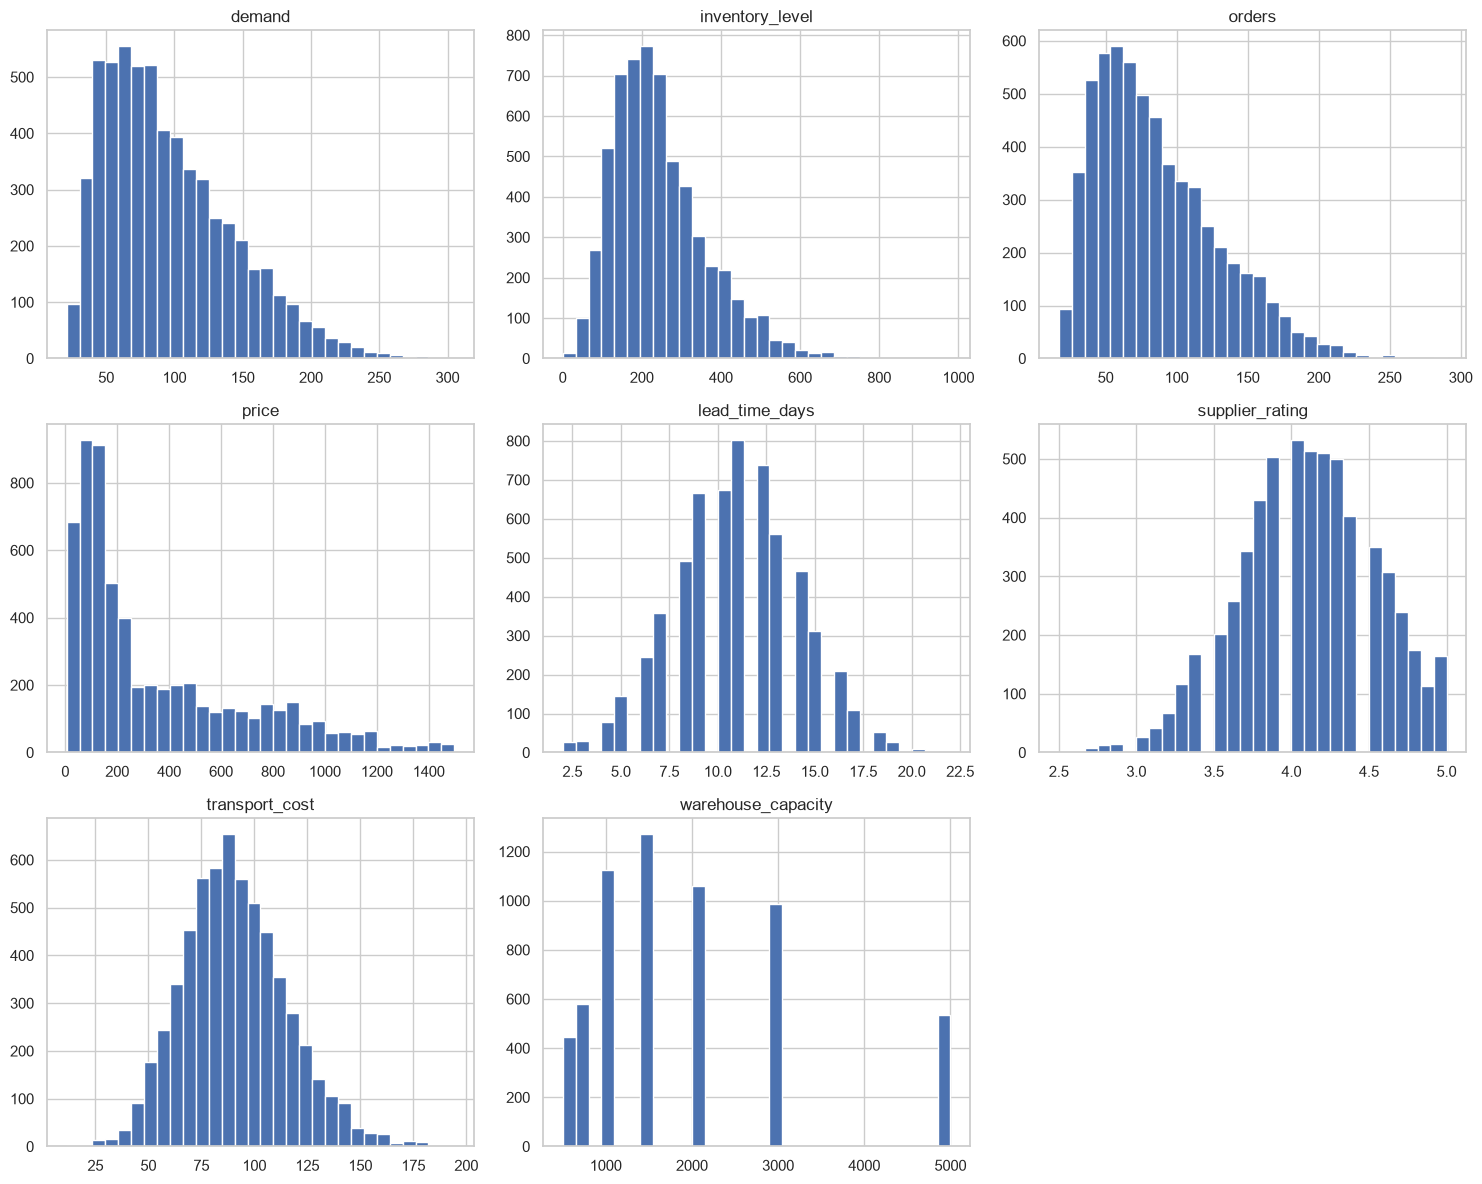

In [23]:
df[numerical_columns].hist(
    figsize=(15, 12),
    bins=30
)

plt.tight_layout()
plt.show()

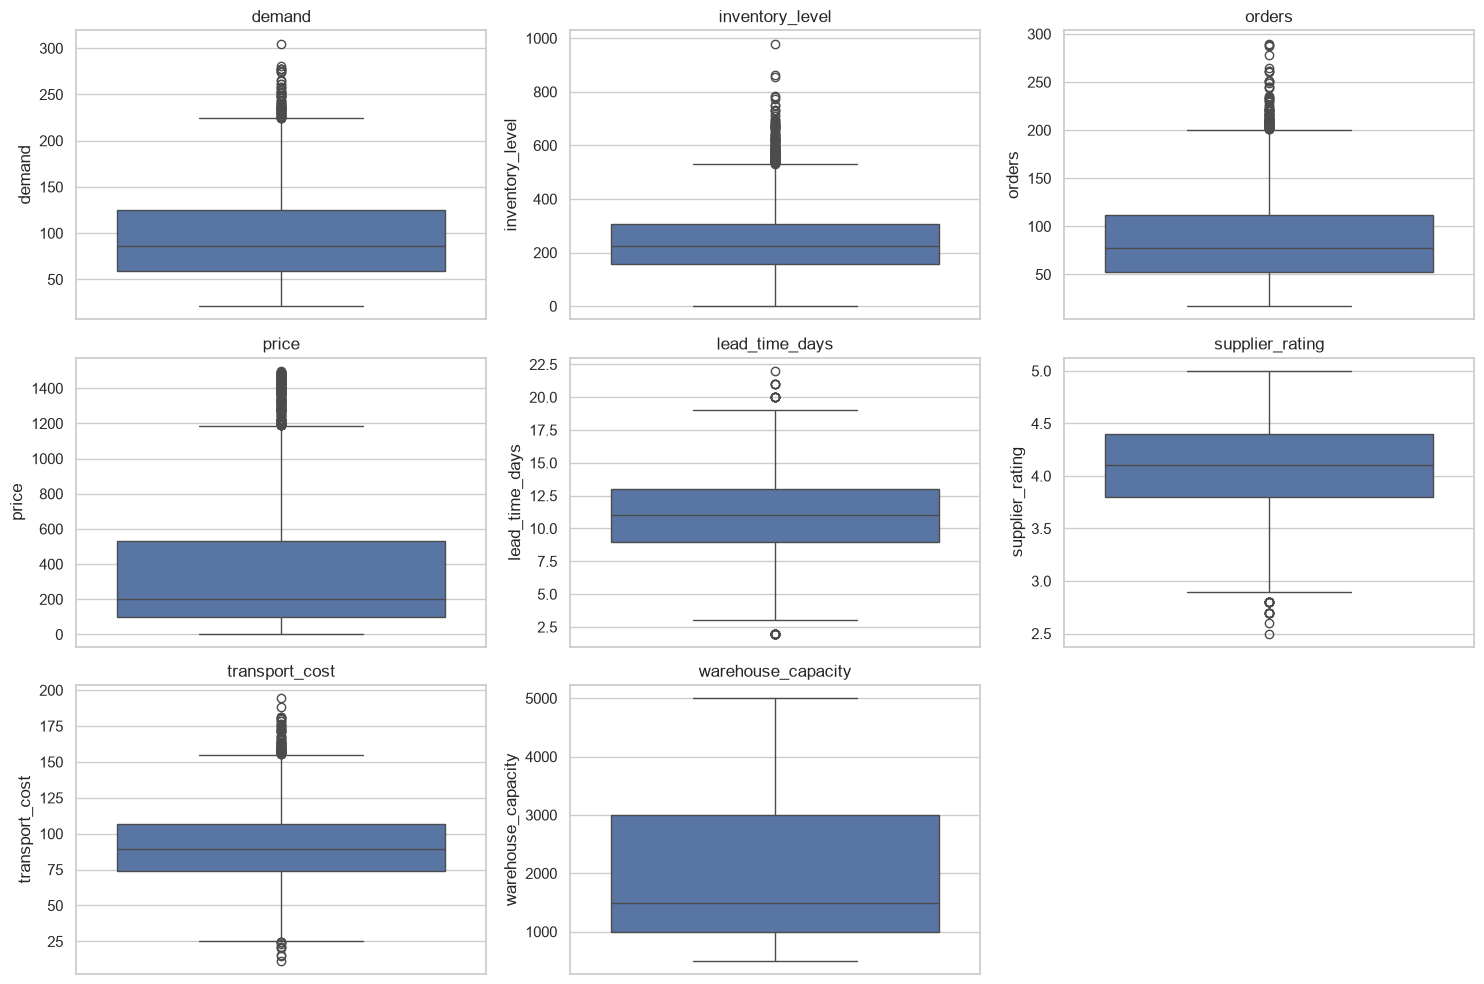

In [24]:
plt.figure(figsize=(15, 10))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(3, 3, i)

    sns.boxplot(
        y=df[column]
    )

    plt.title(column)

plt.tight_layout()
plt.show()

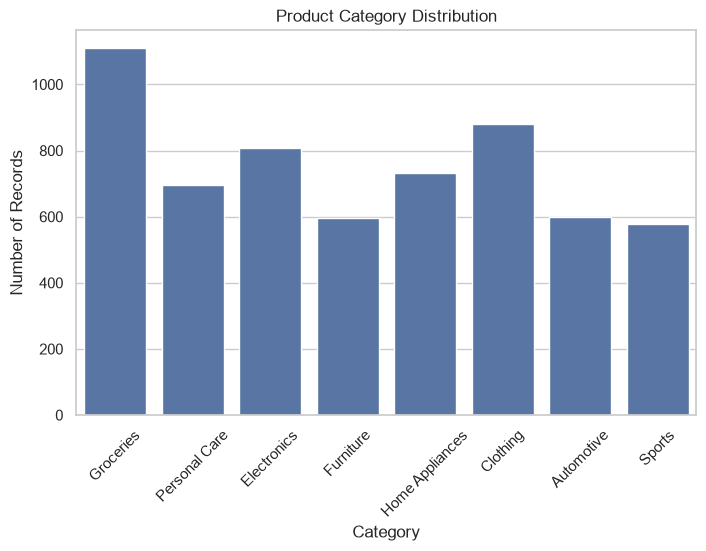

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="category"
)

plt.title("Product Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

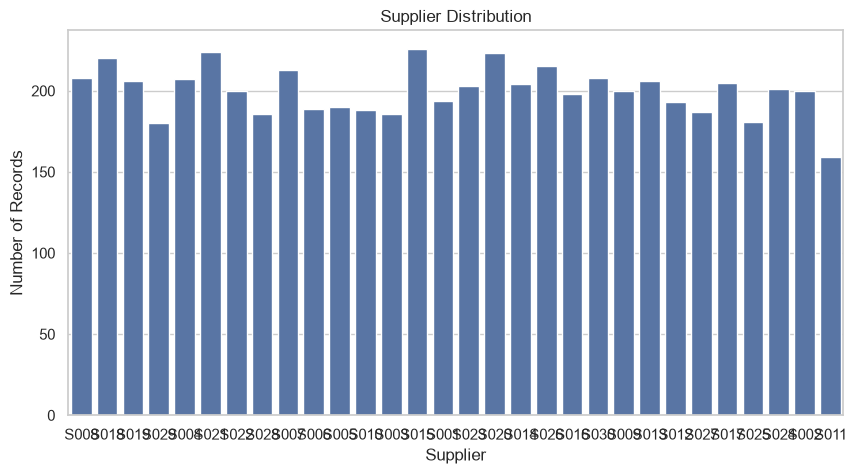

In [26]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="supplier_id"
)

plt.title("Supplier Distribution")
plt.xlabel("Supplier")
plt.ylabel("Number of Records")

plt.show()

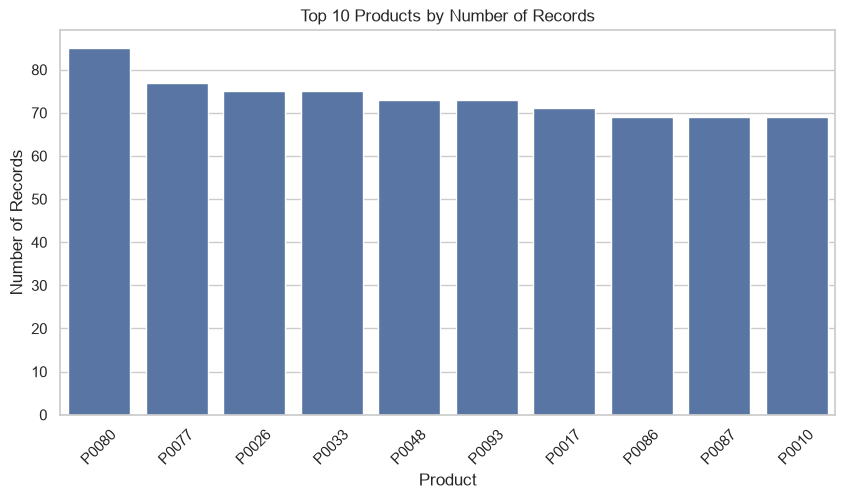

In [27]:
top_products = (
    df["product_id"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_products.index,
    y=top_products.values
)

plt.title("Top 10 Products by Number of Records")
plt.xlabel("Product")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

### Task-wise EDA

##### 1. Demand Forecasting EDA

In [28]:
daily_demand = (
    df.groupby("date")["demand"]
    .sum()
    .reset_index()
)

In [29]:
daily_demand

,date,demand
0,2023-01-01,694
1,2023-01-02,309
2,2023-01-03,311
3,2023-01-04,233
4,2023-01-05,526
...,...,...
1087,2025-12-27,500
1088,2025-12-28,1201
1089,2025-12-29,1095
1090,2025-12-30,702


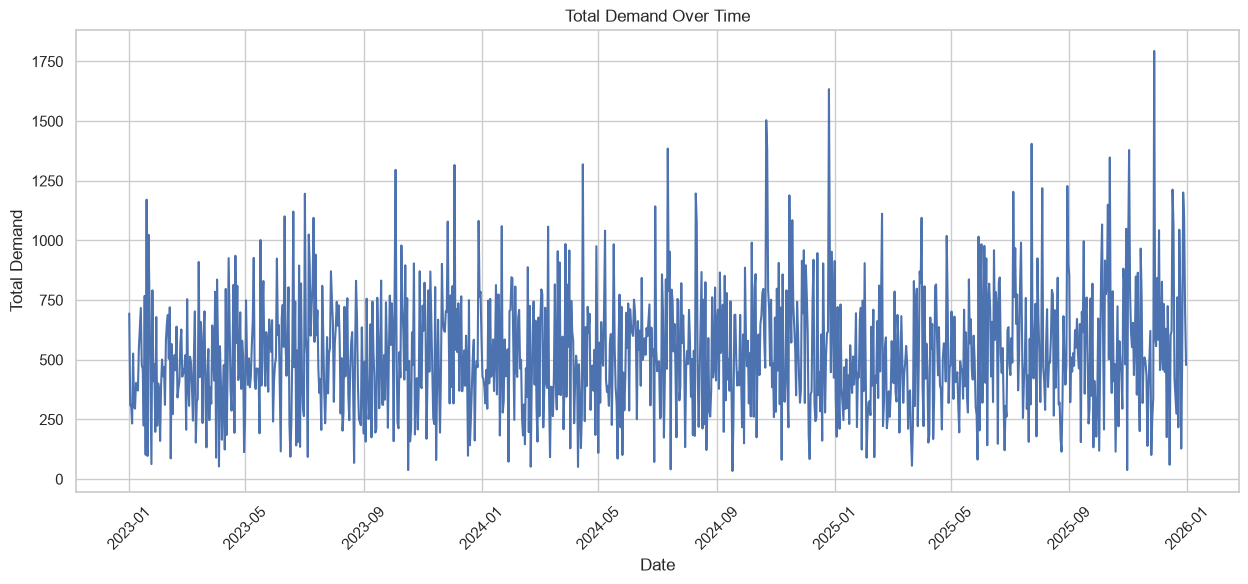

In [30]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_demand["date"],
    daily_demand["demand"]
)

plt.title("Total Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Total Demand")

plt.xticks(rotation=45)

plt.show()

In [31]:
df["Year"] = df["date"].dt.year
df["Month"] = df["date"].dt.month
df["Day"] = df["date"].dt.day
df["Day_of_Week"] = df["date"].dt.day_name()

In [32]:
monthly_demand = (
    df.groupby("Month")["demand"]
    .mean()
)

In [33]:
monthly_demand

Month
1      86.265226
2      89.069663
3      92.026585
4      90.359596
5      85.772556
6      98.329412
7      99.811252
8      92.901768
9      89.793173
10    108.860324
11    111.201699
12    107.217304
Name: demand, dtype: float64

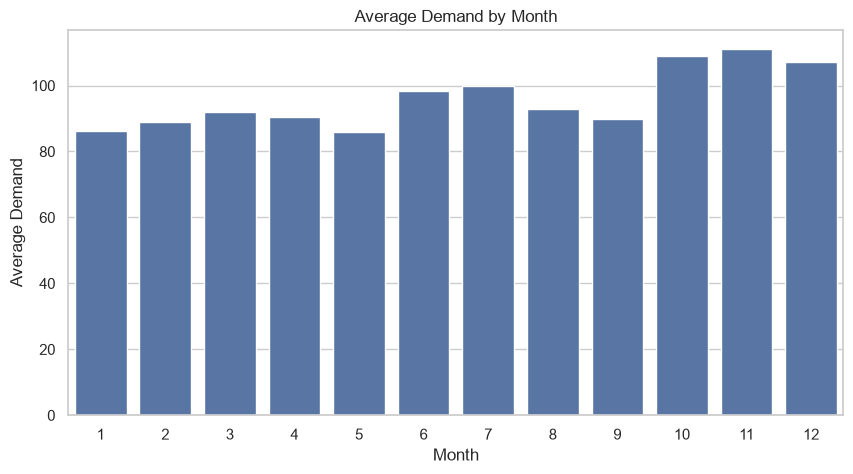

In [34]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_demand.index,
    y=monthly_demand.values
)

plt.title("Average Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Demand")

plt.show()

In [35]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

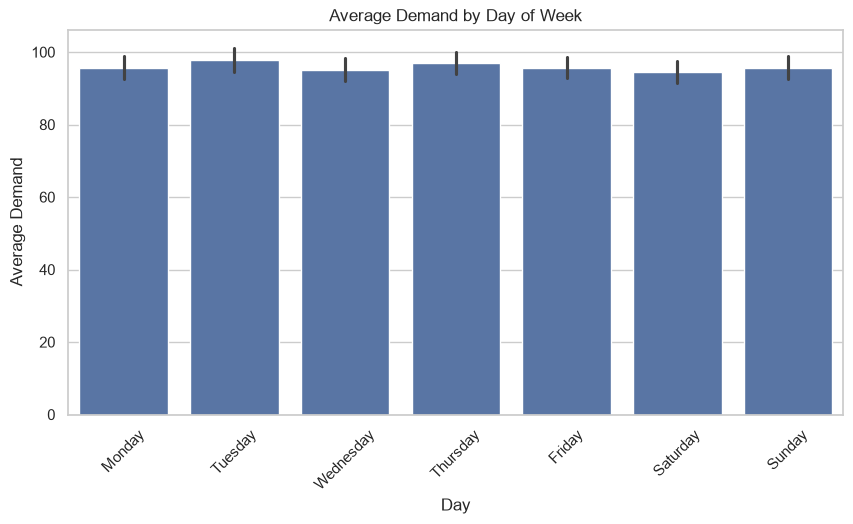

In [36]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Day_of_Week",
    y="demand",
    order=day_order
)

plt.title("Average Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Demand")

plt.xticks(rotation=45)

plt.show()

In [37]:
category_demand = (
    df.groupby("category")["demand"]
    .mean()
    .sort_values(ascending=False)
)
print(category_demand)

category
Groceries          161.921551
Personal Care      127.556671
Clothing           104.488055
Electronics         86.576733
Sports              74.640760
Home Appliances     63.899045
Automotive          52.045151
Furniture           40.264657
Name: demand, dtype: float64


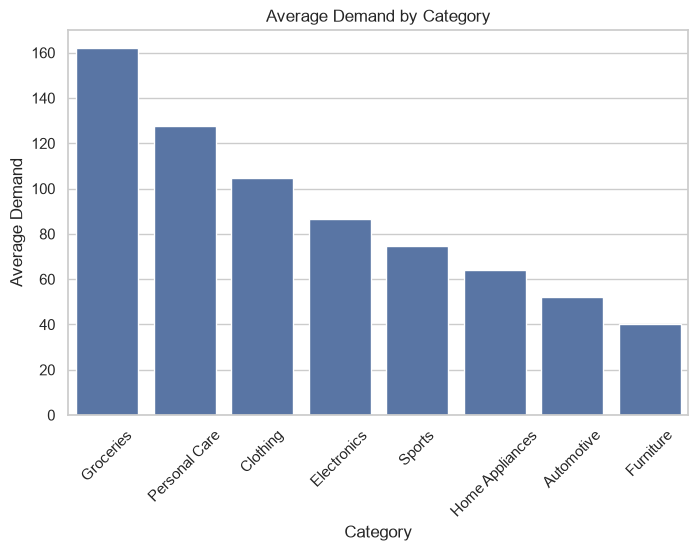

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_demand.index,
    y=category_demand.values
)

plt.title("Average Demand by Category")
plt.xlabel("Category")
plt.ylabel("Average Demand")

plt.xticks(rotation=45)

plt.show()

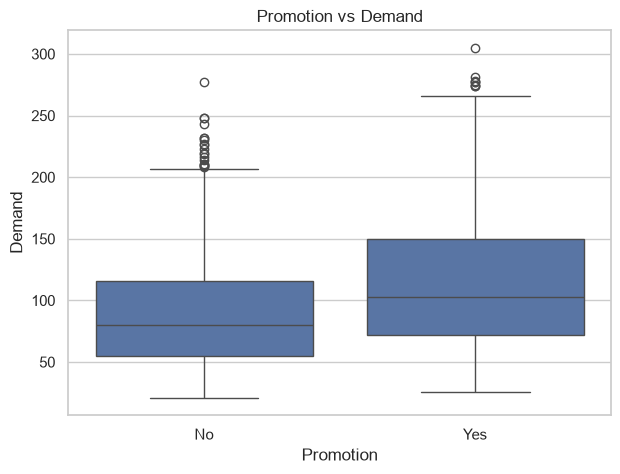

In [39]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="promotion",
    y="demand"
)

plt.title("Promotion vs Demand")
plt.xlabel("Promotion")
plt.ylabel("Demand")

plt.show()

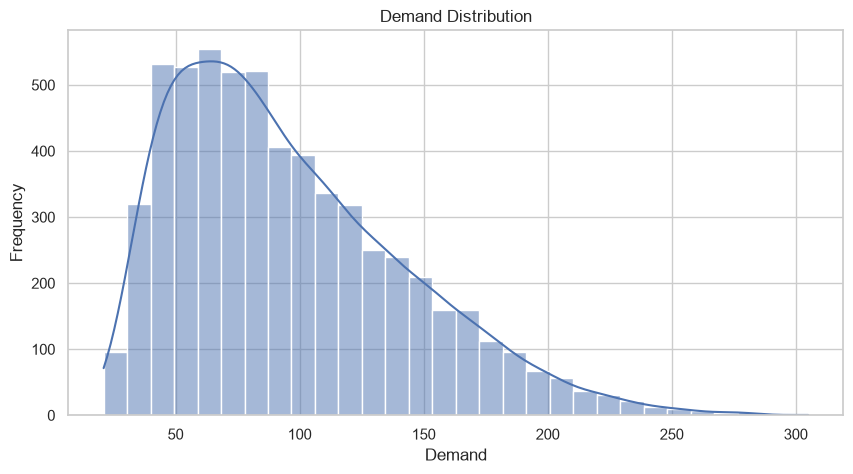

In [40]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="demand",
    bins=30,
    kde=True
)

plt.title("Demand Distribution")
plt.xlabel("Demand")
plt.ylabel("Frequency")

plt.show()

### Task 2

##### STOCK-OUT PREDICTION

In [41]:
stockout_counts = df["stockout"].value_counts()

print(stockout_counts)

stockout
No     5631
Yes     369
Name: count, dtype: int64


In [42]:
stockout_percentage = (
    df["stockout"]
    .value_counts(normalize=True)
    * 100
).round(2)

print(stockout_percentage)

stockout
No     93.85
Yes     6.15
Name: proportion, dtype: float64


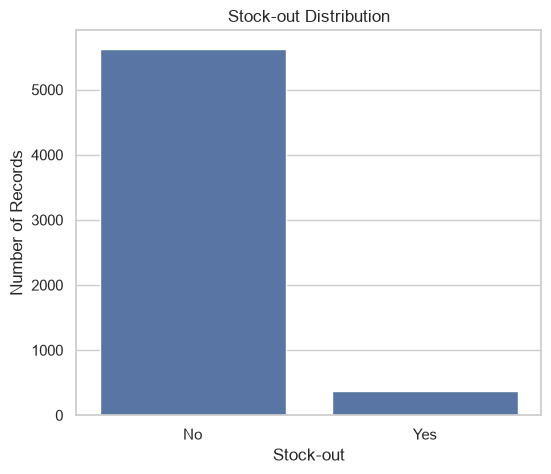

In [43]:
plt.figure(figsize=(6, 5))

sns.countplot(
    data=df,
    x="stockout"
)

plt.title("Stock-out Distribution")
plt.xlabel("Stock-out")
plt.ylabel("Number of Records")

plt.show()

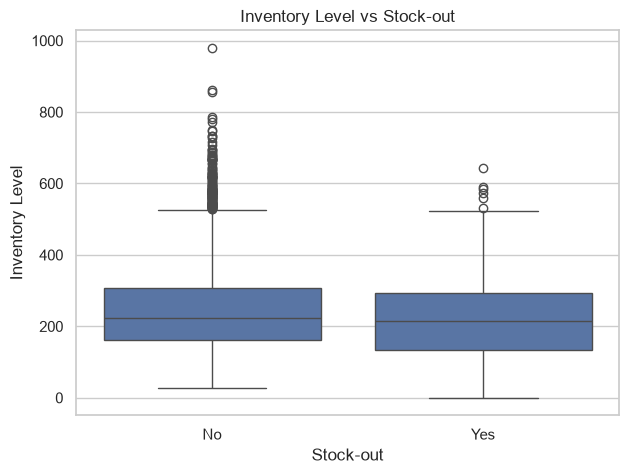

In [44]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="stockout",
    y="inventory_level"
)

plt.title("Inventory Level vs Stock-out")
plt.xlabel("Stock-out")
plt.ylabel("Inventory Level")

plt.show()

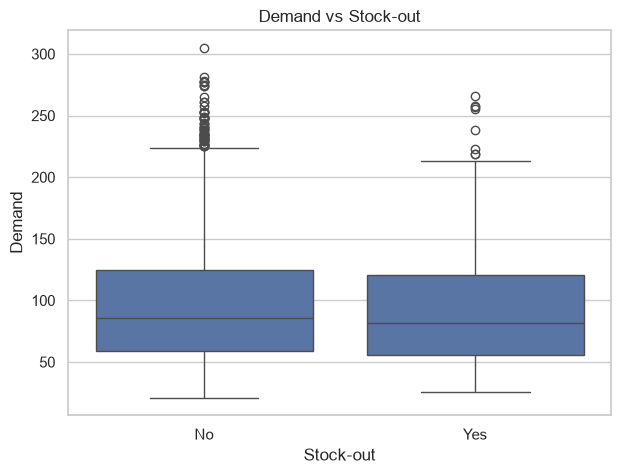

In [45]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="stockout",
    y="demand"
)

plt.title("Demand vs Stock-out")
plt.xlabel("Stock-out")
plt.ylabel("Demand")

plt.show()

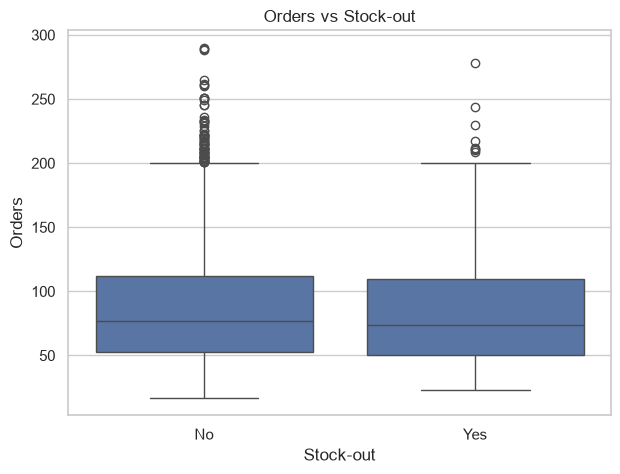

In [46]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="stockout",
    y="orders"
)

plt.title("Orders vs Stock-out")
plt.xlabel("Stock-out")
plt.ylabel("Orders")

plt.show()

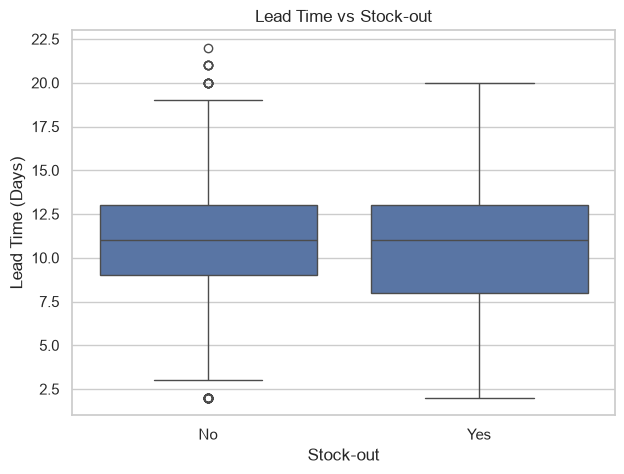

In [47]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="stockout",
    y="lead_time_days"
)

plt.title("Lead Time vs Stock-out")
plt.xlabel("Stock-out")
plt.ylabel("Lead Time (Days)")

plt.show()

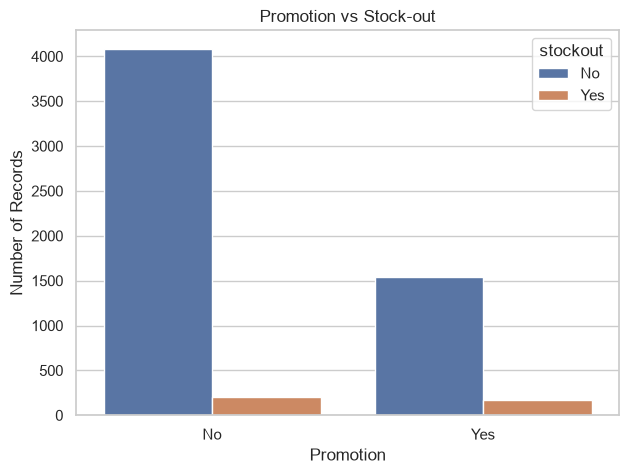

In [48]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="promotion",
    hue="stockout"
)

plt.title("Promotion vs Stock-out")
plt.xlabel("Promotion")
plt.ylabel("Number of Records")

plt.show()

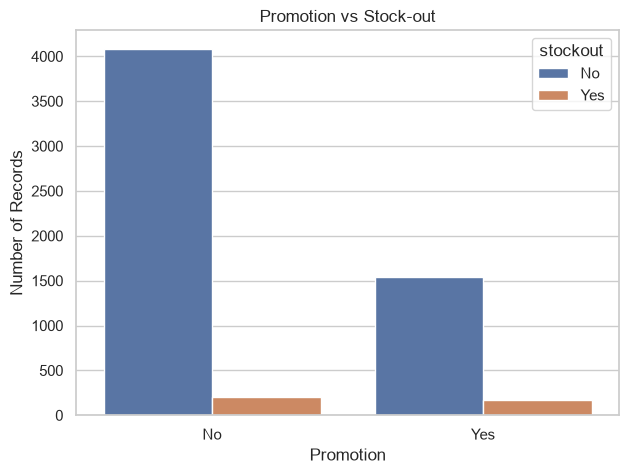

In [49]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="promotion",
    hue="stockout"
)

plt.title("Promotion vs Stock-out")
plt.xlabel("Promotion")
plt.ylabel("Number of Records")

plt.show()

In [50]:
stockout_summary = (
    df.groupby("stockout")[
        [
            "demand",
            "inventory_level",
            "orders",
            "price",
            "lead_time_days",
            "supplier_rating",
            "transport_cost"
        ]
    ]
    .mean()
)

stockout_summary

,demand,inventory_level,orders,price,lead_time_days,supplier_rating,transport_cost
stockout,,,,,,,
No,96.059492,245.502575,86.165157,349.720709,10.817084,4.102184,90.828881
Yes,93.718157,225.701897,84.780488,399.070650,10.764228,4.098374,90.874743


#### Task 3

#####  ANOMALY DETECTION

In [51]:
anomaly_df = pd.read_csv('supply_chain_anomaly_6000.csv')

In [52]:
anomaly_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                6000 non-null   str    
 1   product_id          6000 non-null   str    
 2   category            6000 non-null   str    
 3   supplier_id         6000 non-null   str    
 4   demand              6000 non-null   int64  
 5   inventory_level     6000 non-null   int64  
 6   orders              6000 non-null   int64  
 7   price               6000 non-null   float64
 8   promotion           6000 non-null   str    
 9   lead_time_days      6000 non-null   int64  
 10  supplier_rating     6000 non-null   float64
 11  transport_cost      6000 non-null   float64
 12  warehouse_capacity  6000 non-null   int64  
 13  stockout            6000 non-null   str    
 14  is_anomaly          6000 non-null   int64  
 15  anomaly_type        6000 non-null   str    
dtypes: float64(3), in

In [53]:
anomaly_df["date"] = pd.to_datetime(
    anomaly_df["date"])

In [54]:
anomaly_df["date"].dtype

dtype('<M8[us]')

In [55]:
anomaly_df.shape

(6000, 16)

In [56]:
anomaly_df.columns

Index(['date', 'product_id', 'category', 'supplier_id', 'demand',
       'inventory_level', 'orders', 'price', 'promotion', 'lead_time_days',
       'supplier_rating', 'transport_cost', 'warehouse_capacity', 'stockout',
       'is_anomaly', 'anomaly_type'],
      dtype='str')

In [57]:
anomaly_df.isnull().sum()

date                  0
product_id            0
category              0
supplier_id           0
demand                0
inventory_level       0
orders                0
price                 0
promotion             0
lead_time_days        0
supplier_rating       0
transport_cost        0
warehouse_capacity    0
stockout              0
is_anomaly            0
anomaly_type          0
dtype: int64

In [58]:
anomaly_df.describe()

,date,demand,inventory_level,orders,price,lead_time_days,supplier_rating,transport_cost,warehouse_capacity,is_anomaly
count,6000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,2024-07-06 12:54:00,98.538500,241.822500,89.198167,368.659908,11.242833,4.084517,94.324802,1887.075000,0.080000
min,2023-01-01 00:00:00,21.000000,0.000000,17.000000,5.010000,2.000000,0.500000,11.410000,50.000000,0.000000
25%,2023-10-04 00:00:00,59.000000,156.000000,53.000000,99.325000,9.000000,3.800000,74.045000,1000.000000,0.000000
50%,2024-07-10 00:00:00,87.000000,222.000000,77.000000,204.700000,11.000000,4.100000,89.535000,1500.000000,0.000000
75%,2025-04-11 00:00:00,126.000000,306.000000,113.000000,542.365000,13.000000,4.400000,107.040000,3000.000000,0.000000
max,2025-12-31 00:00:00,1057.000000,980.000000,924.000000,8894.340000,73.000000,5.000000,821.680000,5000.000000,1.000000
std,NaN,57.468461,120.662453,56.302287,423.515892,5.437505,0.507298,44.936363,1237.517701,0.271316


In [59]:
print(
    "Duplicate rows:",
    anomaly_df.duplicated().sum()
)

Duplicate rows: 0


In [60]:
print("Start Date:", anomaly_df["date"].min())
print("End Date:", anomaly_df["date"].max())

print(
    "Number of unique dates:",
    anomaly_df["date"].nunique())

Start Date: 2023-01-01 00:00:00
End Date: 2025-12-31 00:00:00
Number of unique dates: 1092


In [61]:
anomaly_df["is_anomaly"].value_counts()


is_anomaly
0    5520
1     480
Name: count, dtype: int64

In [62]:
anomaly_df["is_anomaly"].value_counts(normalize=True).mul(100).round(2)

is_anomaly
0    92.0
1     8.0
Name: proportion, dtype: float64

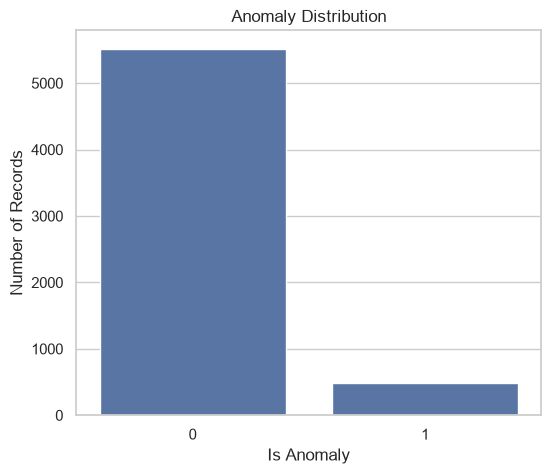

In [63]:
plt.figure(figsize=(6, 5))

sns.countplot(
    data=anomaly_df,
    x="is_anomaly"
)

plt.title("Anomaly Distribution")
plt.xlabel("Is Anomaly")
plt.ylabel("Number of Records")

plt.show()

In [64]:
anomaly_df["anomaly_type"].value_counts()


anomaly_type
Normal                      5520
High Price                    60
High Demand                   60
High Transport Cost           60
Low Warehouse Capacity        60
Low Inventory                 60
High Orders                   60
Abnormal Supplier Rating      60
Long Lead Time                60
Name: count, dtype: int64

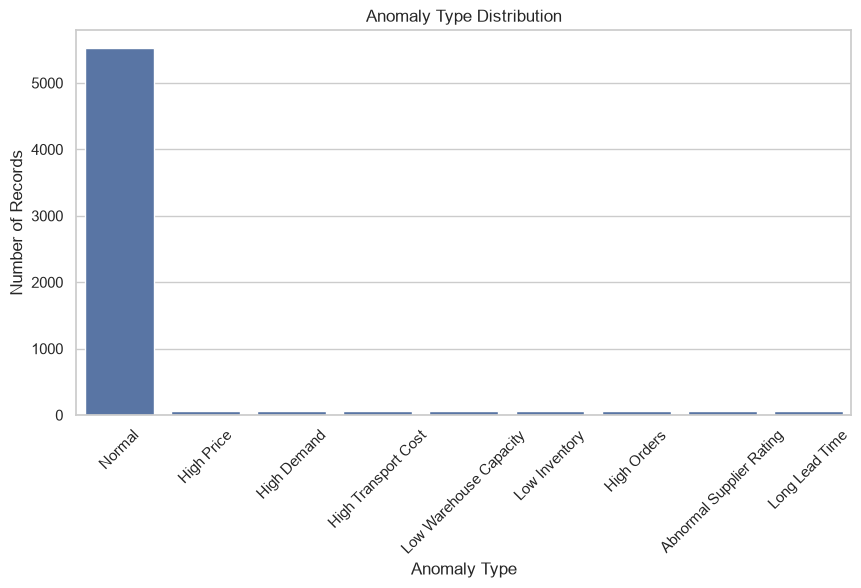

In [65]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=anomaly_df,
    x="anomaly_type"
)

plt.title("Anomaly Type Distribution")
plt.xlabel("Anomaly Type")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

In [66]:
anomaly_numeric = [
    "demand",
    "inventory_level",
    "orders",
    "price",
    "lead_time_days",
    "supplier_rating",
    "transport_cost",
    "warehouse_capacity"
]

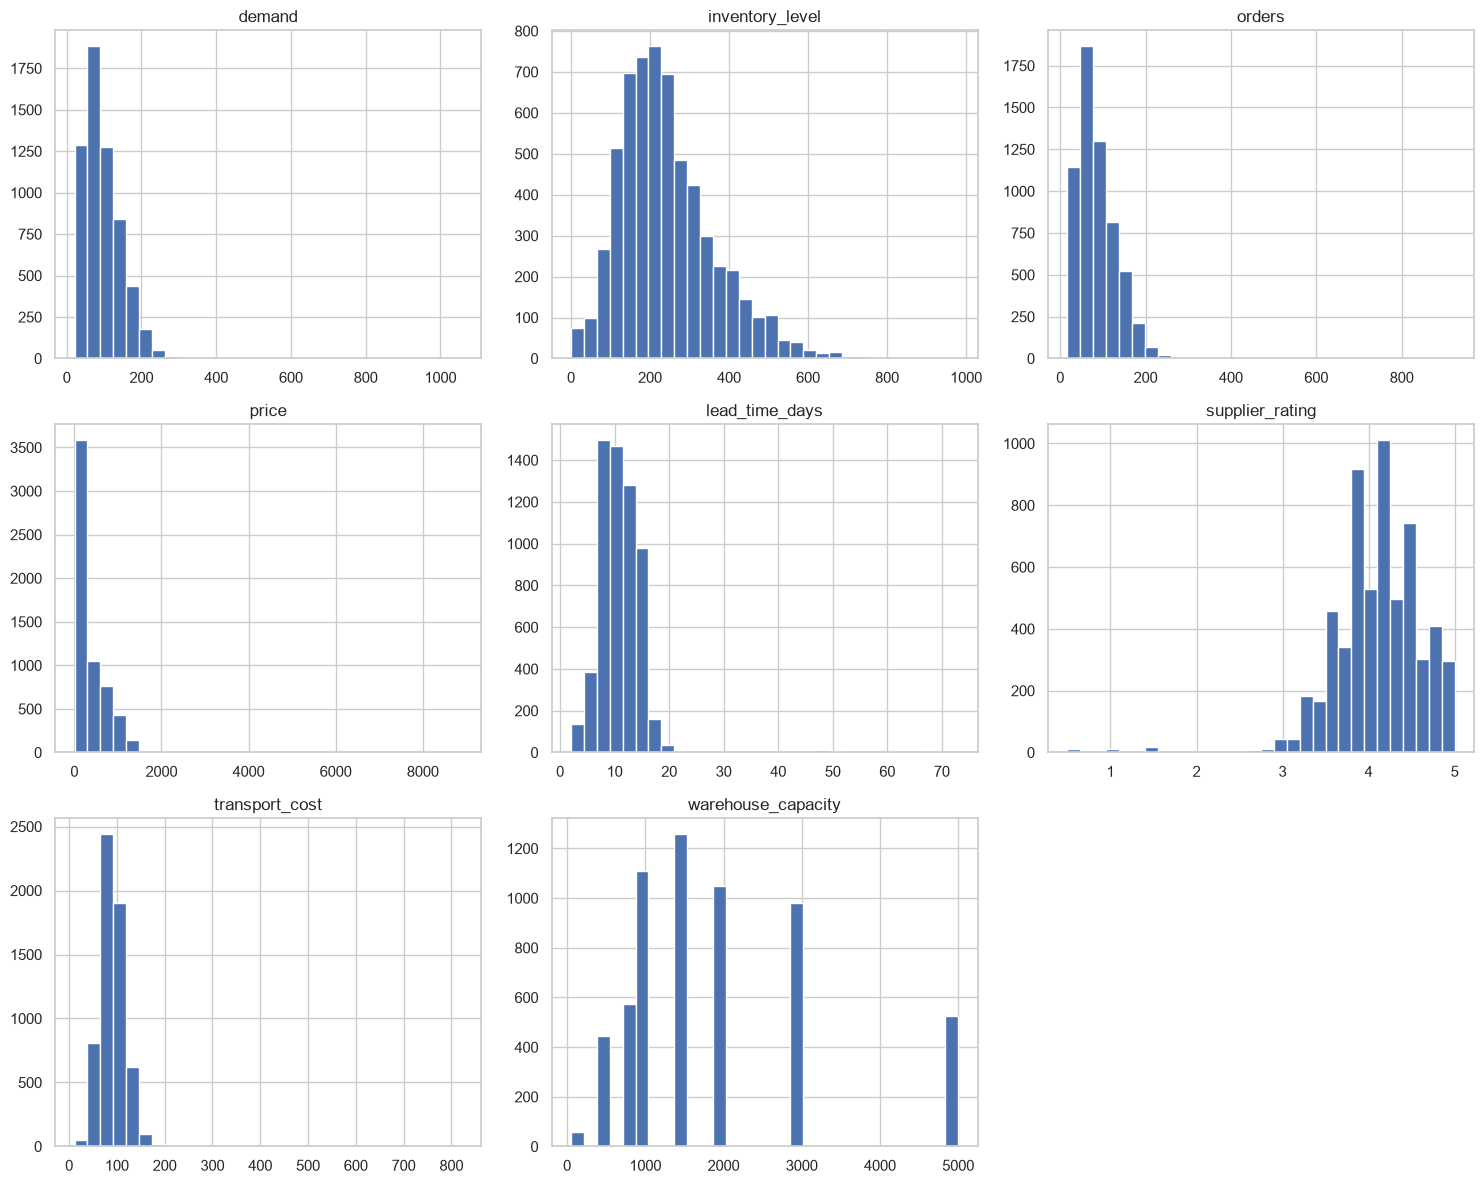

In [67]:
anomaly_df[anomaly_numeric].hist(
    figsize=(15, 12),
    bins=30
)

plt.tight_layout()
plt.show()

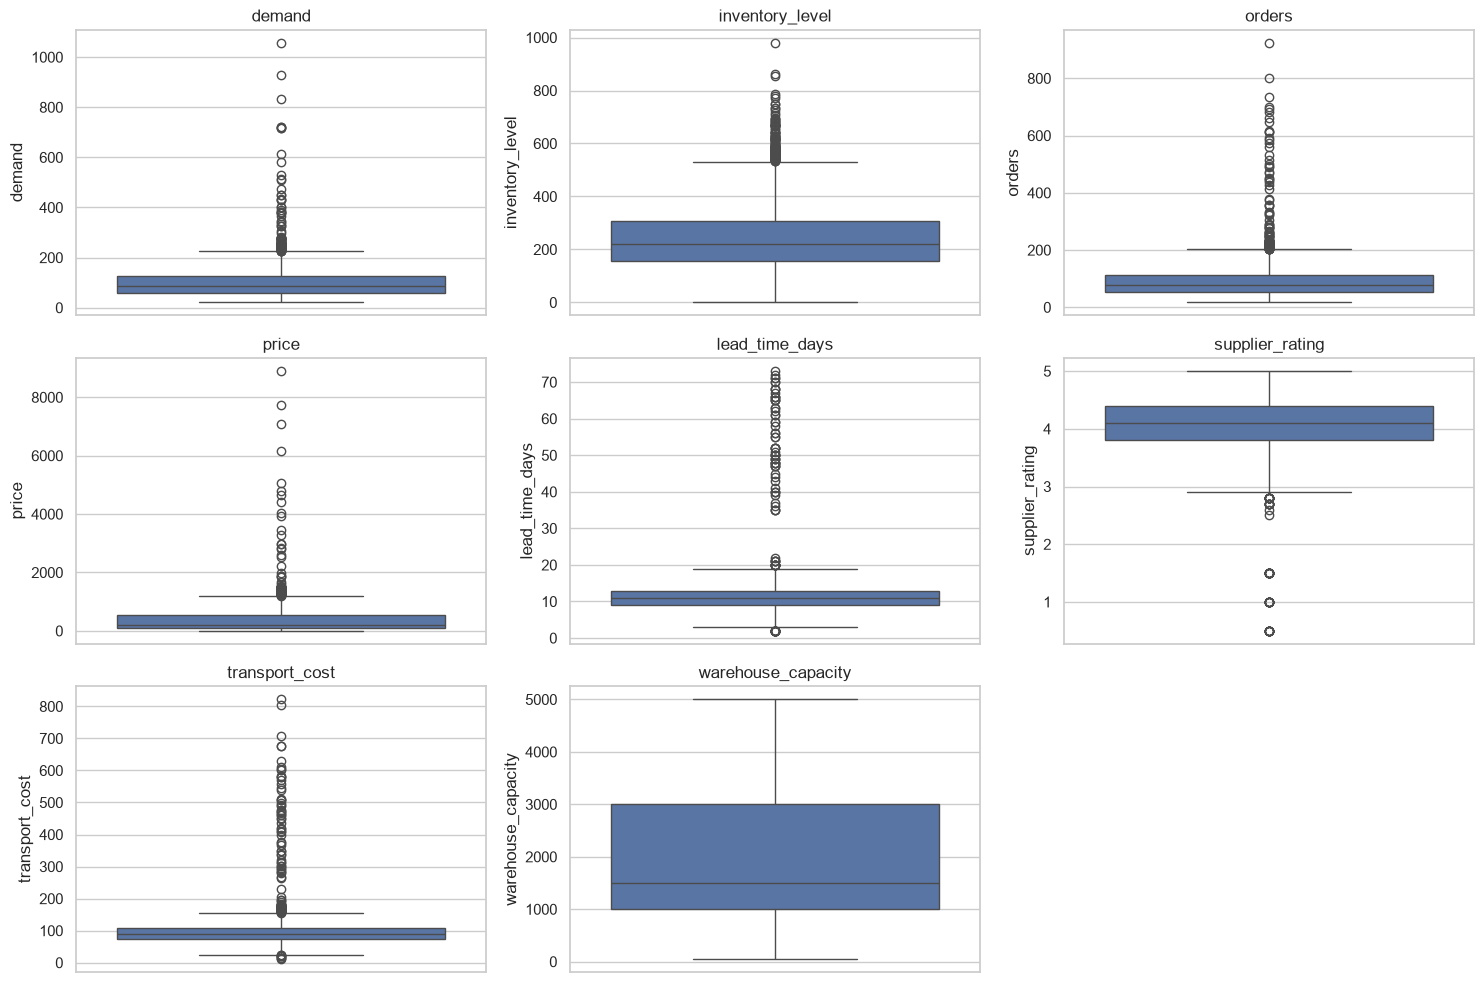

In [68]:
plt.figure(figsize=(15, 10))

for i, column in enumerate(anomaly_numeric, 1):

    plt.subplot(3, 3, i)

    sns.boxplot(
        y=anomaly_df[column]
    )

    plt.title(column)

plt.tight_layout()
plt.show()

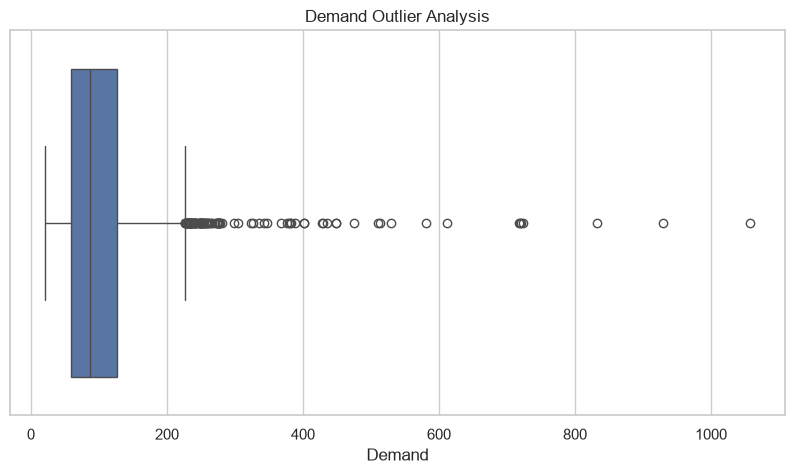

In [69]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=anomaly_df["demand"]
)

plt.title("Demand Outlier Analysis")
plt.xlabel("Demand")

plt.show()

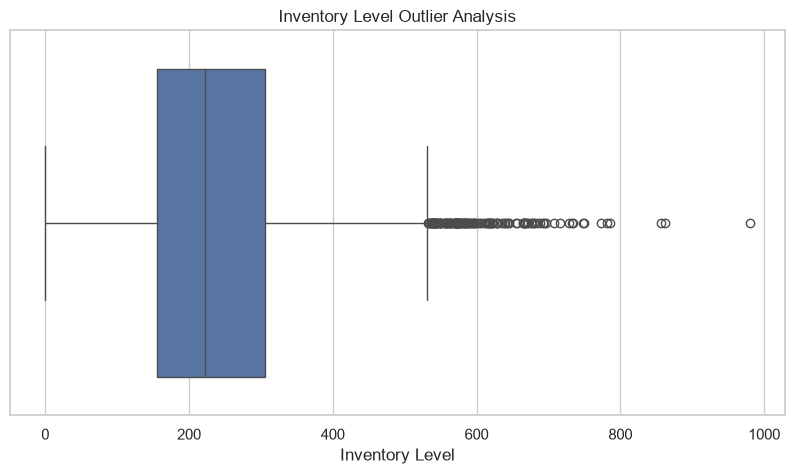

In [70]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=anomaly_df["inventory_level"]
)

plt.title("Inventory Level Outlier Analysis")
plt.xlabel("Inventory Level")

plt.show()

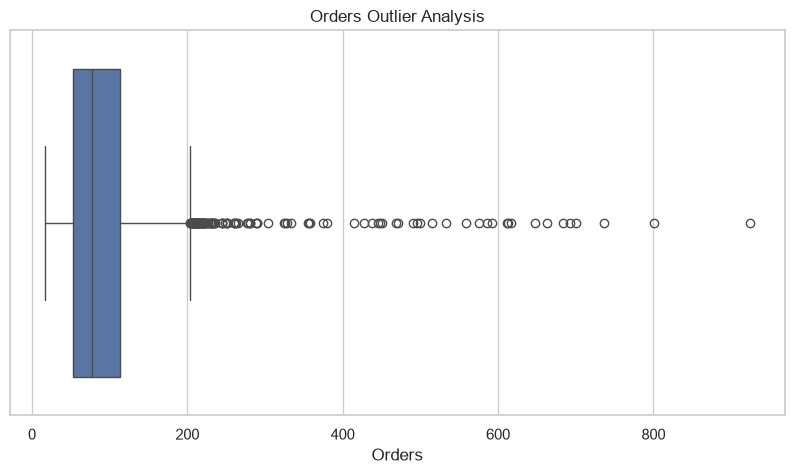

In [71]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=anomaly_df["orders"]
)

plt.title("Orders Outlier Analysis")
plt.xlabel("Orders")

plt.show()

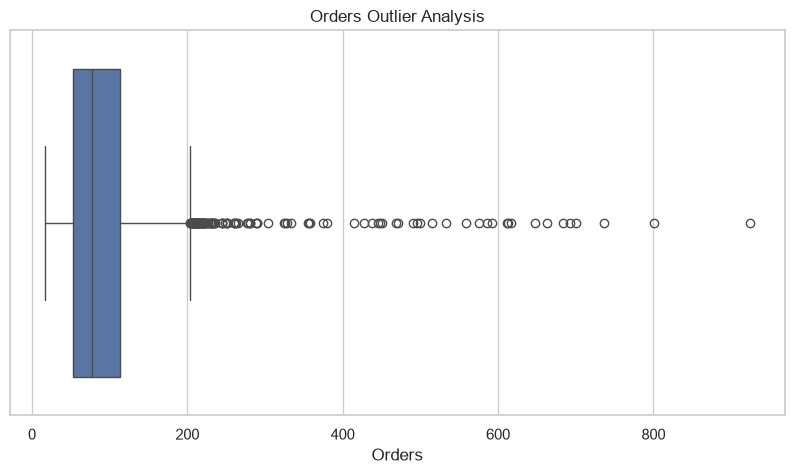

In [72]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=anomaly_df["orders"]
)

plt.title("Orders Outlier Analysis")
plt.xlabel("Orders")

plt.show()

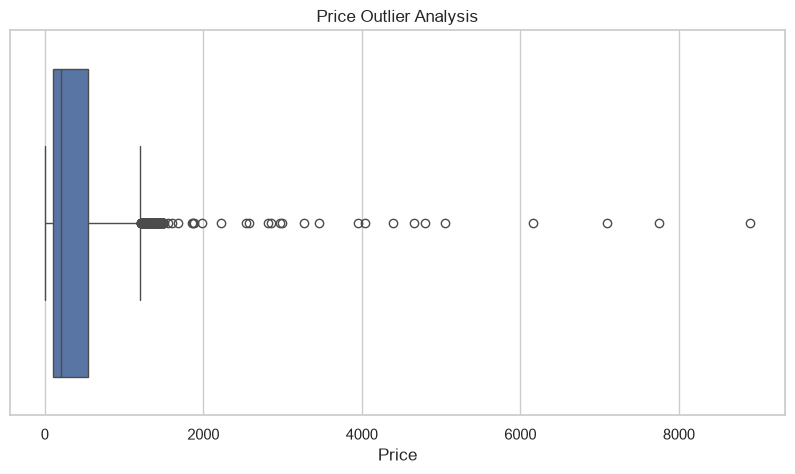

In [73]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=anomaly_df["price"]
)

plt.title("Price Outlier Analysis")
plt.xlabel("Price")

plt.show()

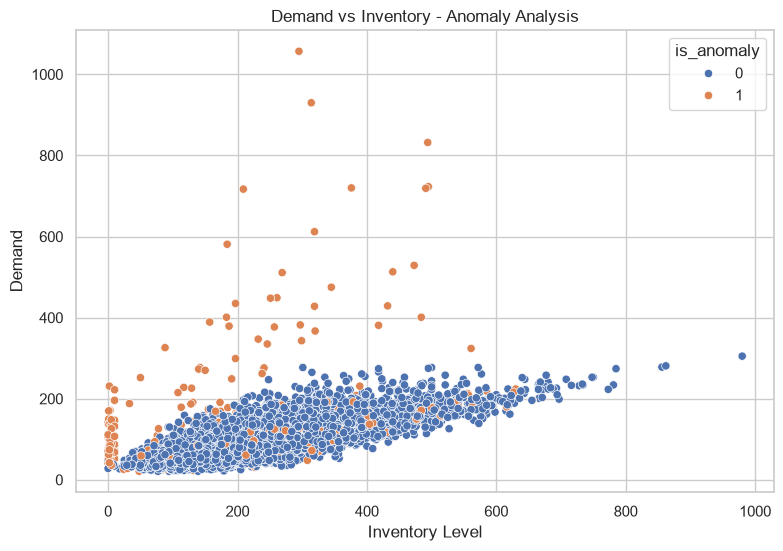

In [74]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=anomaly_df,
    x="inventory_level",
    y="demand",
    hue="is_anomaly"
)

plt.title("Demand vs Inventory - Anomaly Analysis")
plt.xlabel("Inventory Level")
plt.ylabel("Demand")

plt.show()

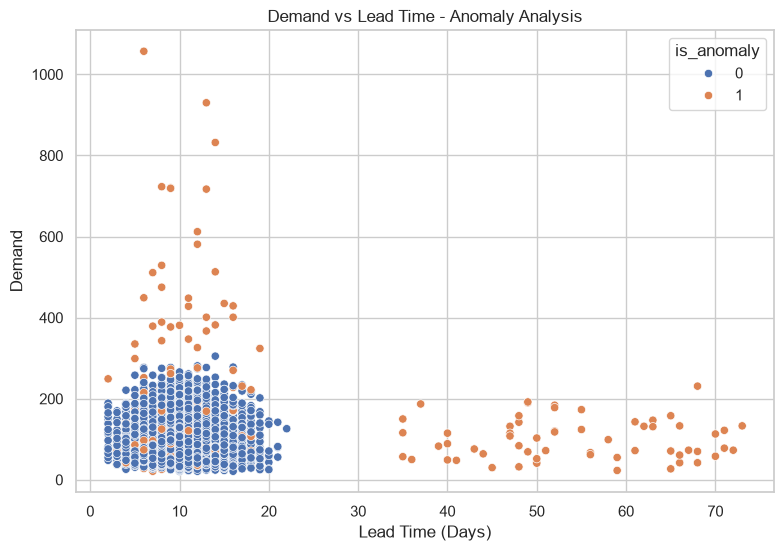

In [75]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=anomaly_df,
    x="lead_time_days",
    y="demand",
    hue="is_anomaly"
)

plt.title("Demand vs Lead Time - Anomaly Analysis")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Demand")

plt.show()

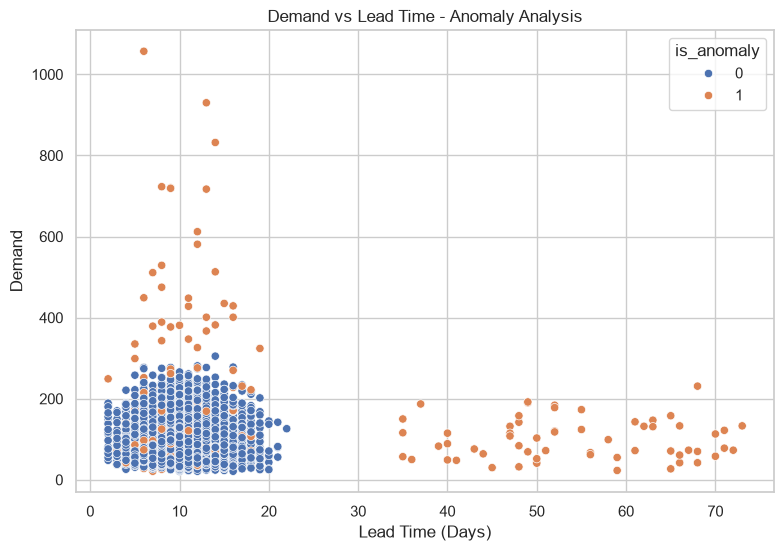

In [76]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=anomaly_df,
    x="lead_time_days",
    y="demand",
    hue="is_anomaly"
)

plt.title("Demand vs Lead Time - Anomaly Analysis")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Demand")

plt.show()

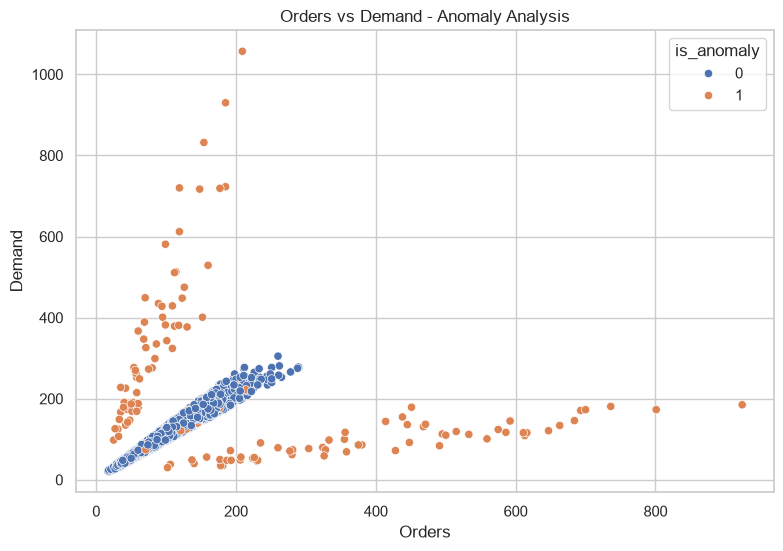

In [77]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=anomaly_df,
    x="orders",
    y="demand",
    hue="is_anomaly"
)

plt.title("Orders vs Demand - Anomaly Analysis")
plt.xlabel("Orders")
plt.ylabel("Demand")

plt.show()

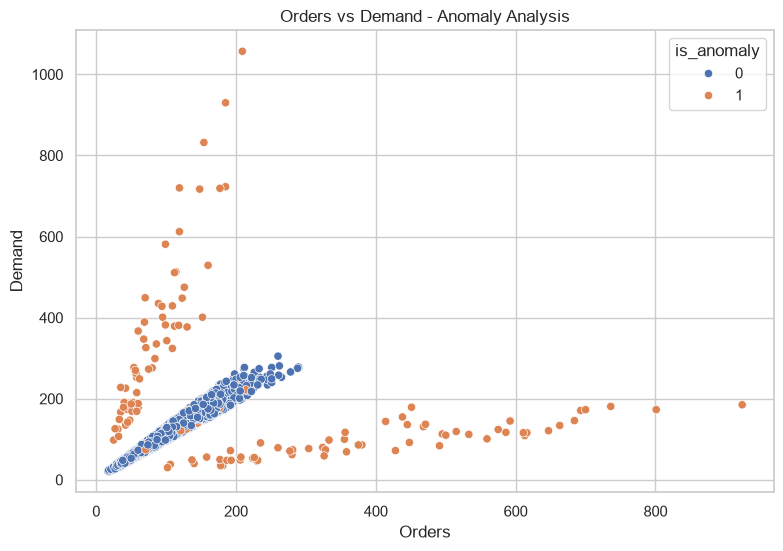

In [78]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=anomaly_df,
    x="orders",
    y="demand",
    hue="is_anomaly"
)

plt.title("Orders vs Demand - Anomaly Analysis")
plt.xlabel("Orders")
plt.ylabel("Demand")

plt.show()

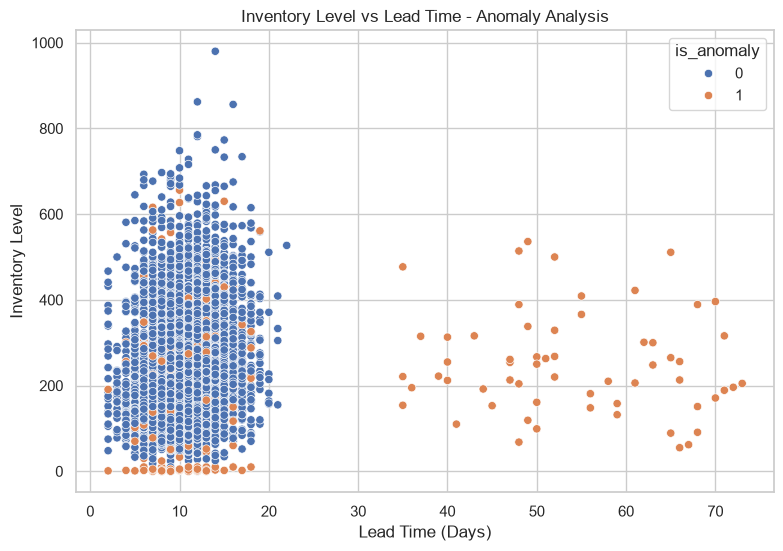

In [79]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=anomaly_df,
    x="lead_time_days",
    y="inventory_level",
    hue="is_anomaly"
)

plt.title("Inventory Level vs Lead Time - Anomaly Analysis")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Inventory Level")

plt.show()

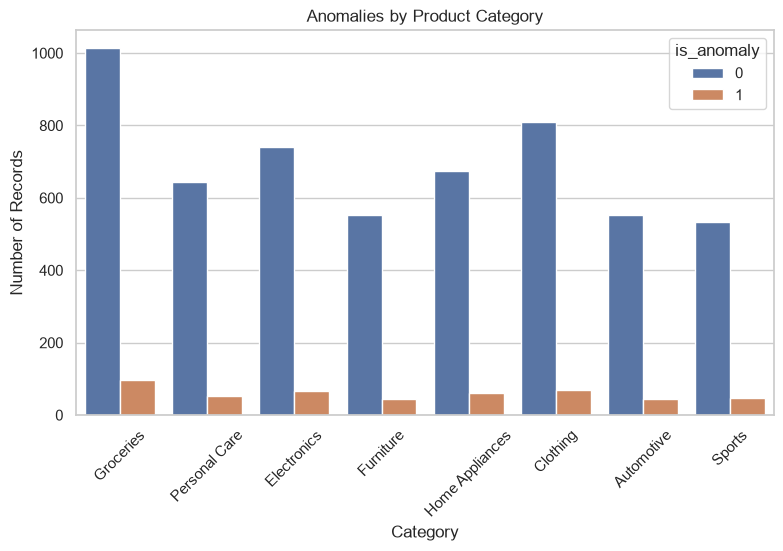

In [80]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=anomaly_df,
    x="category",
    hue="is_anomaly"
)

plt.title("Anomalies by Product Category")
plt.xlabel("Category")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

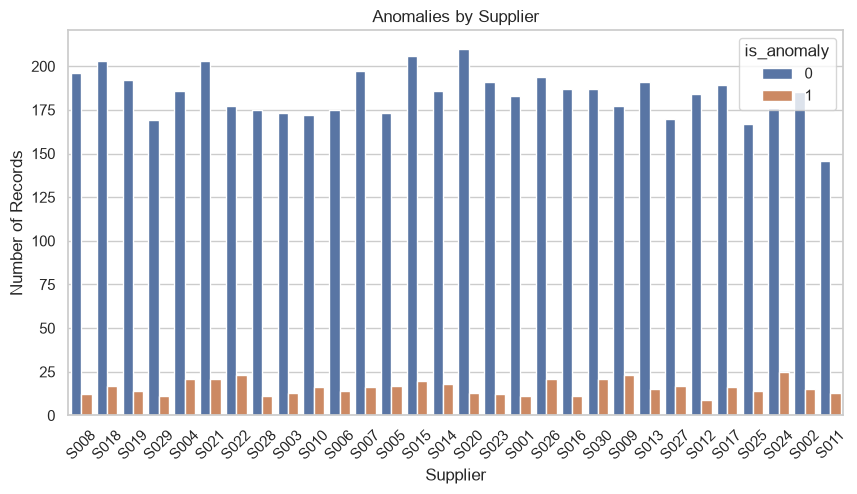

In [81]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=anomaly_df,
    x="supplier_id",
    hue="is_anomaly"
)

plt.title("Anomalies by Supplier")
plt.xlabel("Supplier")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

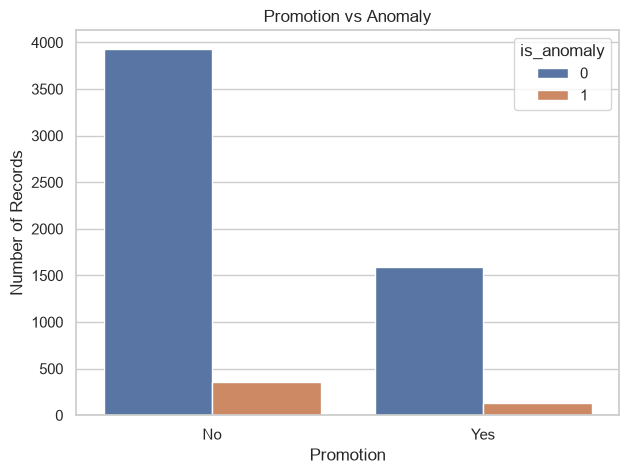

In [82]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=anomaly_df,
    x="promotion",
    hue="is_anomaly"
)

plt.title("Promotion vs Anomaly")
plt.xlabel("Promotion")
plt.ylabel("Number of Records")

plt.show()

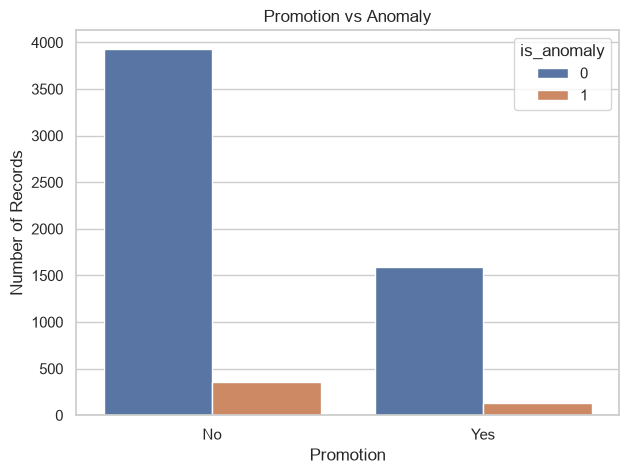

In [83]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=anomaly_df,
    x="promotion",
    hue="is_anomaly"
)

plt.title("Promotion vs Anomaly")
plt.xlabel("Promotion")
plt.ylabel("Number of Records")

plt.show()

In [96]:
print(anomaly_df[correlation_columns].dtypes)

demand                  int64
inventory_level         int64
orders                  int64
price                 float64
promotion                 str
lead_time_days          int64
supplier_rating       float64
transport_cost        float64
warehouse_capacity      int64
stockout                int64
dtype: object


In [90]:
print(anomaly_df["stockout"].unique())

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


In [92]:
anomaly_df["stockout"] = anomaly_df["stockout"].map({
    "No": 0,
    "Yes": 1})

In [97]:
anomaly_df["promotion"] = anomaly_df["promotion"].map({
    "No": 0,
    "Yes": 1})

In [98]:
correlation_columns = [
    "demand",
    "inventory_level",
    "orders",
    "price",
    "promotion",
    "lead_time_days",
    "supplier_rating",
    "transport_cost",
    "warehouse_capacity",
    "stockout"
]




In [99]:
correlation_matrix = anomaly_df[correlation_columns].corr()
correlation_matrix

,demand,inventory_level,orders,price,promotion,lead_time_days,supplier_rating,transport_cost,warehouse_capacity,stockout
demand,1.000000,0.629553,0.640715,-0.380838,0.212136,-0.008682,-0.007593,-0.135787,0.013725,-0.011016
inventory_level,0.629553,1.000000,0.576305,-0.328474,0.196019,0.073733,-0.041717,-0.056580,-0.005412,-0.106933
orders,0.640715,0.576305,1.000000,-0.351750,0.175520,-0.001346,0.005705,-0.121146,0.006634,0.006723
price,-0.380838,-0.328474,-0.351750,1.000000,0.004799,-0.005656,0.003590,0.130440,-0.009738,0.013088
promotion,0.212136,0.196019,0.175520,0.004799,1.000000,-0.000829,0.006501,-0.003601,0.005845,0.086206
lead_time_days,-0.008682,0.073733,-0.001346,-0.005656,-0.000829,1.000000,-0.164350,0.231091,0.000087,0.001081
supplier_rating,-0.007593,-0.041717,0.005705,0.003590,0.006501,-0.164350,1.000000,-0.096685,0.019420,0.011622
transport_cost,-0.135787,-0.056580,-0.121146,0.130440,-0.003601,0.231091,-0.096685,1.000000,-0.003539,-0.023620
warehouse_capacity,0.013725,-0.005412,0.006634,-0.009738,0.005845,0.000087,0.019420,-0.003539,1.000000,0.021880
stockout,-0.011016,-0.106933,0.006723,0.013088,0.086206,0.001081,0.011622,-0.023620,0.021880,1.000000


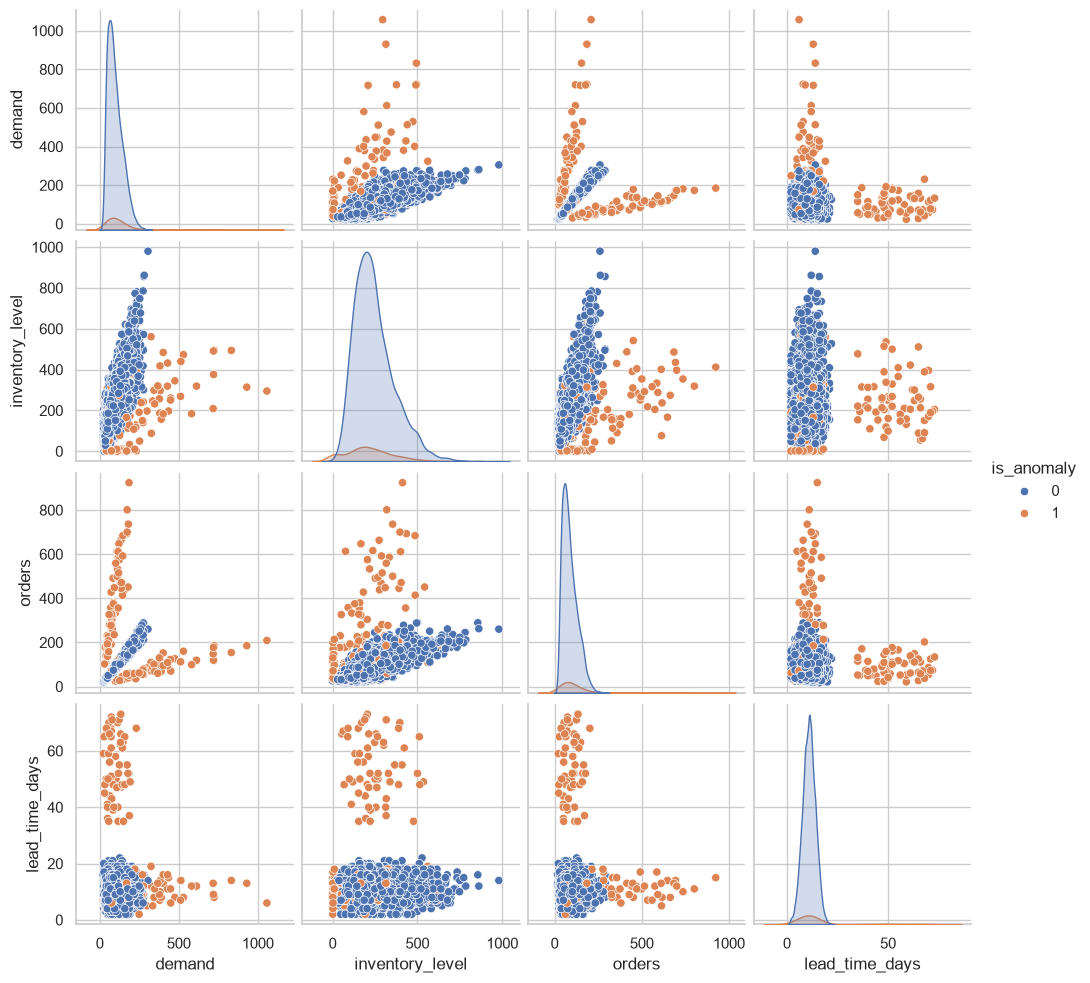

In [100]:
sns.pairplot(
    anomaly_df[
        [
            "demand",
            "inventory_level",
            "orders",
            "lead_time_days",
            "is_anomaly"
        ]
    ],
    hue="is_anomaly"
)

plt.show()

In [101]:
def count_outliers(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return len(outliers)

In [102]:
for column in anomaly_numeric:

    print(
        column,
        ":",
        count_outliers(anomaly_df, column),
        "potential outliers"
    )

demand : 102 potential outliers
inventory_level : 133 potential outliers
orders : 121 potential outliers
price : 166 potential outliers
lead_time_days : 100 potential outliers
supplier_rating : 60 potential outliers
transport_cost : 132 potential outliers
warehouse_capacity : 0 potential outliers


In [103]:
comparison = (
    anomaly_df
    .groupby("is_anomaly")[
        [
            "demand",
            "inventory_level",
            "orders",
            "price",
            "lead_time_days",
            "supplier_rating",
            "transport_cost",
            "warehouse_capacity"
        ]
    ]
    .mean()
)

comparison

,demand,inventory_level,orders,price,lead_time_days,supplier_rating,transport_cost,warehouse_capacity
is_anomaly,,,,,,,,
0,95.898732,244.262681,86.072645,353.478866,10.830435,4.100797,90.900440,1909.103261
1,128.895833,213.760417,125.141667,543.241896,15.985417,3.897292,133.704958,1633.750000


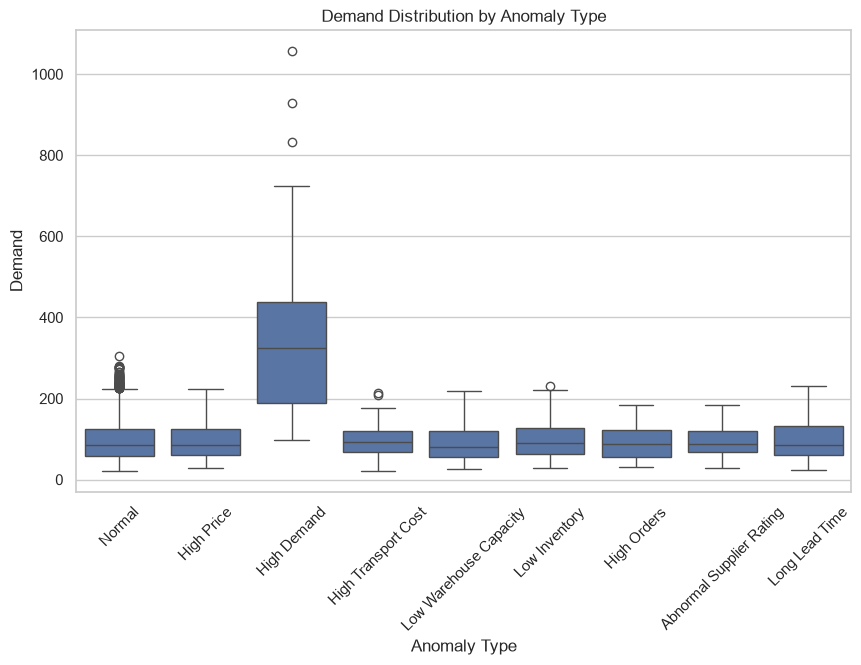

In [104]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=anomaly_df,
    x="anomaly_type",
    y="demand"
)

plt.title("Demand Distribution by Anomaly Type")
plt.xlabel("Anomaly Type")
plt.ylabel("Demand")

plt.xticks(rotation=45)

plt.show()

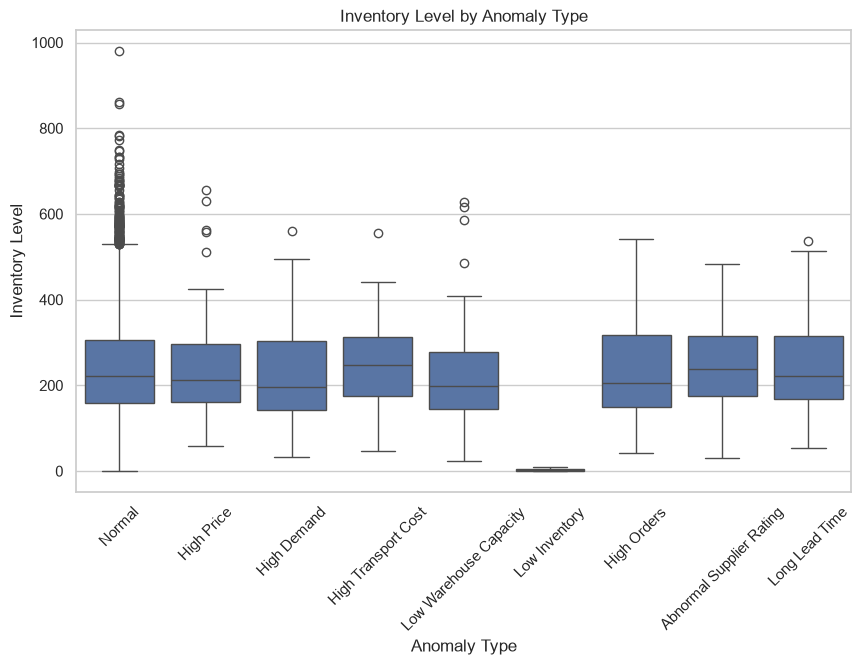

In [105]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=anomaly_df,
    x="anomaly_type",
    y="inventory_level"
)

plt.title("Inventory Level by Anomaly Type")
plt.xlabel("Anomaly Type")
plt.ylabel("Inventory Level")

plt.xticks(rotation=45)

plt.show()

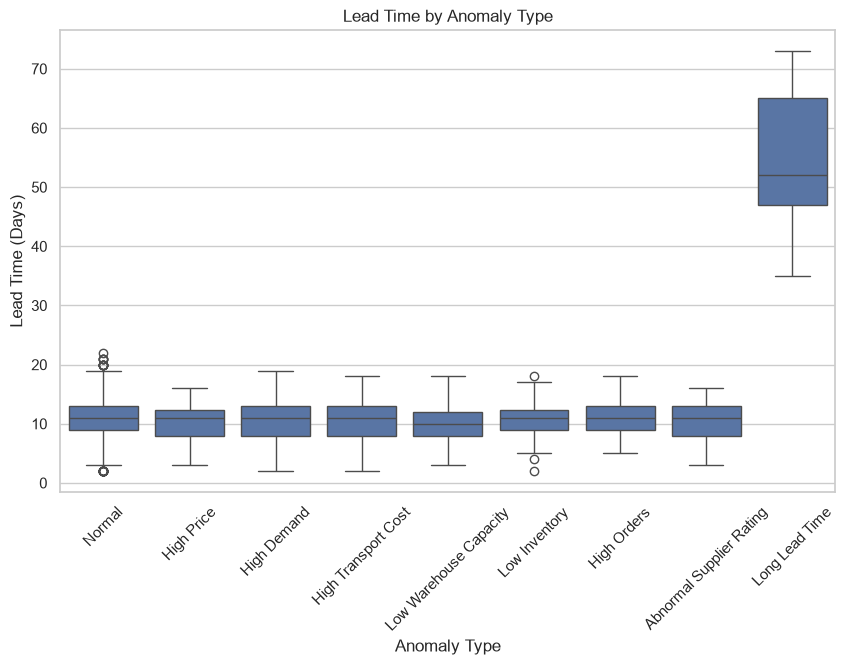

In [106]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=anomaly_df,
    x="anomaly_type",
    y="lead_time_days"
)

plt.title("Lead Time by Anomaly Type")
plt.xlabel("Anomaly Type")
plt.ylabel("Lead Time (Days)")

plt.xticks(rotation=45)

plt.show()

In [107]:
daily_anomalies = (
    anomaly_df
    .groupby("date")["is_anomaly"]
    .sum()
    .reset_index()
)

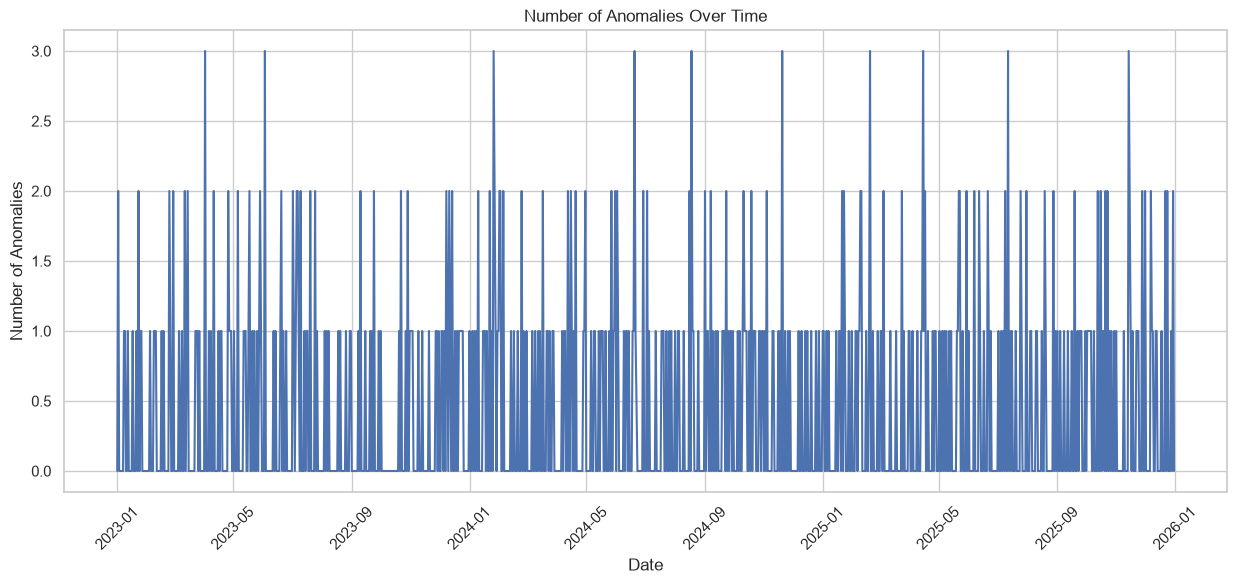

In [108]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_anomalies["date"],
    daily_anomalies["is_anomaly"]
)

plt.title("Number of Anomalies Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Anomalies")

plt.xticks(rotation=45)

plt.show()

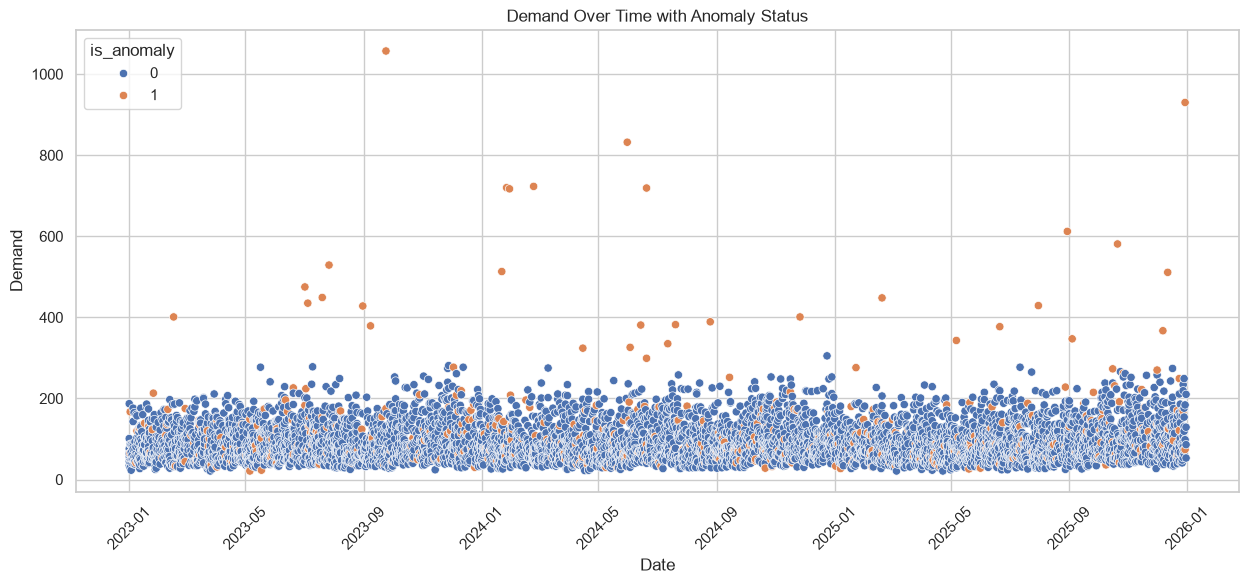

In [109]:
plt.figure(figsize=(15, 6))

sns.scatterplot(
    data=anomaly_df,
    x="date",
    y="demand",
    hue="is_anomaly"
)

plt.title("Demand Over Time with Anomaly Status")
plt.xlabel("Date")
plt.ylabel("Demand")

plt.xticks(rotation=45)

plt.show()

In [110]:
anomalies = anomaly_df[
    anomaly_df["is_anomaly"] == 1
]

print(
    "Number of anomalies:",
    len(anomalies)
)

anomalies.head(20)

Number of anomalies: 480


,date,product_id,category,supplier_id,demand,inventory_level,orders,price,promotion,lead_time_days,supplier_rating,transport_cost,warehouse_capacity,stockout,is_anomaly,anomaly_type
12,2023-01-02,P0009,Sports,S006,65,161,67,1881.25,1,4,4.4,48.20,5000,1,1,High Price
13,2023-01-02,P0072,Automotive,S007,167,198,35,185.10,0,12,4.6,111.86,5000,0,1,High Demand
38,2023-01-08,P0019,Home Appliances,S016,41,131,34,4396.56,0,10,4.8,108.12,2000,0,1,High Price
44,2023-01-09,P0078,Groceries,S007,120,297,110,79.91,0,14,4.0,629.14,5000,0,1,High Transport Cost
66,2023-01-12,P0051,Personal Care,S016,126,293,108,140.54,0,12,4.3,571.08,750,0,1,High Transport Cost
89,2023-01-17,P0091,Groceries,S024,139,274,115,693.72,0,10,4.6,83.41,1500,0,1,High Price
119,2023-01-21,P0043,Groceries,S021,130,331,110,7.88,0,5,4.6,67.65,50,0,1,Low Warehouse Capacity
131,2023-01-23,P0044,Automotive,S008,58,122,48,954.50,1,5,4.3,71.85,100,0,1,Low Warehouse Capacity
132,2023-01-23,P0013,Home Appliances,S004,67,10,68,216.43,0,8,4.8,83.39,2000,1,1,Low Inventory
143,2023-01-25,P0016,Groceries,S023,123,146,107,140.30,0,11,3.9,76.44,50,0,1,Low Warehouse Capacity


In [111]:
anomaly_df.sort_values(
    by="demand",
    ascending=False
)[
    [
        "date",
        "product_id",
        "category",
        "demand",
        "inventory_level",
        "orders",
        "lead_time_days",
        "is_anomaly",
        "anomaly_type"
    ]
].head(20)

,date,product_id,category,demand,inventory_level,orders,lead_time_days,is_anomaly,anomaly_type
1435,2023-09-24,P0087,Groceries,1057,295,209,6,1,High Demand
5995,2025-12-30,P0051,Groceries,930,314,185,13,1,High Demand
2779,2024-05-31,P0086,Groceries,832,494,154,14,1,High Demand
2241,2024-02-24,P0069,Groceries,723,495,185,8,1,High Demand
2092,2024-01-27,P0020,Groceries,720,376,119,9,1,High Demand
2891,2024-06-20,P0063,Groceries,719,491,177,9,1,High Demand
2102,2024-01-30,P0030,Groceries,717,209,148,13,1,High Demand
5333,2025-08-30,P0080,Personal Care,612,319,119,12,1,High Demand
5627,2025-10-21,P0014,Sports,581,184,99,12,1,High Demand
1122,2023-07-27,P0086,Groceries,529,473,160,8,1,High Demand


In [112]:
pd.crosstab(
    anomaly_df["is_anomaly"],
    anomaly_df["anomaly_type"]
)

anomaly_type,Abnormal Supplier Rating,High Demand,High Orders,High Price,High Transport Cost,Long Lead Time,Low Inventory,Low Warehouse Capacity,Normal
is_anomaly,,,,,,,,,
0,0,0,0,0,0,0,0,0,5520
1,60,60,60,60,60,60,60,60,0


In [113]:
summary = pd.DataFrame({
    "Feature": anomaly_numeric,

    "Mean": [
        anomaly_df[column].mean()
        for column in anomaly_numeric
    ],

    "Median": [
        anomaly_df[column].median()
        for column in anomaly_numeric
    ],

    "Minimum": [
        anomaly_df[column].min()
        for column in anomaly_numeric
    ],

    "Maximum": [
        anomaly_df[column].max()
        for column in anomaly_numeric
    ]
})

summary

,Feature,Mean,Median,Minimum,Maximum
0,demand,98.538500,87.000,21.00,1057.00
1,inventory_level,241.822500,222.000,0.00,980.00
2,orders,89.198167,77.000,17.00,924.00
3,price,368.659908,204.700,5.01,8894.34
4,lead_time_days,11.242833,11.000,2.00,73.00
5,supplier_rating,4.084517,4.100,0.50,5.00
6,transport_cost,94.324802,89.535,11.41,821.68
7,warehouse_capacity,1887.075000,1500.000,50.00,5000.00



# EDA Insights 

1. Examined the datasets to understand their structure, columns, data types, and statistical properties.

2. Checked for missing values and duplicate records to assess data quality.

3. Analyzed demand distributions to understand demand variations across products.

4. Visualized demand over time to identify trends and possible seasonal patterns.

5. Examined stockout and non-stockout records to understand the distribution of the target variable.

6. Analyzed inventory levels to identify potential shortages and excess inventory.

7. Studied relationships between demand, inventory, and orders to understand supply-demand patterns.

8. Examined lead time, supplier ratings, and transportation costs to identify potentially important operational factors.

9. Used histograms and boxplots to understand numerical feature distributions and identify potential outliers.

10. Analyzed categorical features such as product category, supplier, and promotion status to compare supply-chain patterns.

11. Examined normal and anomalous records to identify differences in operational behavior.

12. Used correlation analysis and scatter plots to explore relationships between supply-chain variables.

13. Analyzed data over time to investigate demand fluctuations and changes in anomaly frequency.

14. Selected suitable input features and planned the necessary preprocessing, including encoding, scaling, and chronological data splitting where appropriate.

15. Prepared the datasets for three deep learning models: LSTM for demand forecasting, MLP for stockout risk prediction, and Autoencoder for anomaly detection. The models will be evaluated using appropriate metrics for each task.
